# Amazon Product Review — Sentiment Analysis



In [6]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text as sk_text
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
sns.set_style("whitegrid")

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load and inspect data

In [8]:
senti =pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Projects/422/train_data.csv')
print(senti.shape)
senti.head()

(34660, 21)


/tmp/ipykernel_1676/2173305845.py:1: DtypeWarning: Columns (1,10) have mixed types. Specify dtype option on import or set low_memory=False.
  senti =pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Projects/422/train_data.csv')


,id,name,asins,brand,categories,keys,manufacturer,reviews.date,reviews.dateAdded,reviews.dateSeen,...,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username
0,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,This product so far has not disappointed. My c...,Kindle,NaN,NaN,Adapter
1,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,great for beginner or experienced person. Boug...,very fast,NaN,NaN,truman
2,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,Inexpensive tablet for him to use and learn on...,Beginner tablet for our 9 year old son.,NaN,NaN,DaveZ
3,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,4.0,http://reviews.bestbuy.com/3545/5620406/review...,I've had my Fire HD 8 two weeks now and I love...,Good!!!,NaN,NaN,Shacks
4,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-12T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,I bought this for my grand daughter when she c...,Fantastic Tablet for kids,NaN,NaN,explore42


In [9]:
senti.isnull().sum()

,0
id,0
name,6760
asins,2
brand,0
categories,0
keys,0
manufacturer,0
reviews.date,39
reviews.dateAdded,10621
reviews.dateSeen,0


## 2. Keep only what we need


In [10]:
senti_data = senti[['reviews.rating', 'reviews.text', 'reviews.title']].dropna(
    subset=['reviews.rating', 'reviews.text']
).reset_index(drop=True)

print(senti_data.shape)
senti_data.isnull().sum()

(34626, 3)


,0
reviews.rating,0
reviews.text,0
reviews.title,6


## 3. Text cleaning



In [11]:
STOPWORDS = sk_text.ENGLISH_STOP_WORDS

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # remove URLs
    t = re.sub(r"[^a-z\s]", " ", t)               # keep letters only
    t = re.sub(r"\s+", " ", t).strip()            # collapse whitespace
    tokens = [w for w in t.split() if w not in STOPWORDS and len(w) > 2]
    return " ".join(tokens)

senti_data['clean_text'] = senti_data['reviews.text'].apply(clean_text)

# Drop rows that became empty after cleaning (e.g. text was only punctuation/stopwords)
senti_data = senti_data[senti_data['clean_text'].str.len() > 0].reset_index(drop=True)
senti_data[['reviews.text', 'clean_text']].head()

,reviews.text,clean_text
0,This product so far has not disappointed. My c...,product far disappointed children love use lik...
1,great for beginner or experienced person. Boug...,great beginner experienced person bought gift ...
2,Inexpensive tablet for him to use and learn on...,inexpensive tablet use learn step nabi thrille...
3,I've had my Fire HD 8 two weeks now and I love...,weeks love tablet great value prime members ta...
4,I bought this for my grand daughter when she c...,bought grand daughter comes visit set user ent...


## 4. Create sentiment labels from star rating

sentiment_label
Positive    32311
Neutral      1499
Negative      810
Name: count, dtype: int64

Class balance (%):
sentiment_label
Positive    93.3
Neutral      4.3
Negative     2.3
Name: count, dtype: float64


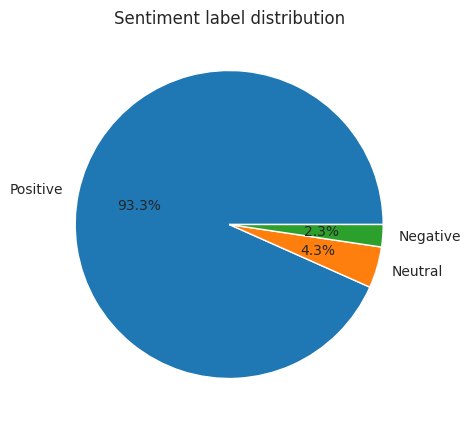

In [12]:
def sentiment_labeler(score):
    if score >= 4:
        return "Positive"
    elif score == 3:
        return "Neutral"
    else:
        return "Negative"

senti_data['sentiment_label'] = senti_data['reviews.rating'].apply(sentiment_labeler)

label_counts = senti_data['sentiment_label'].value_counts()
print(label_counts)
print("\nClass balance (%):")
print((label_counts / len(senti_data) * 100).round(1))

label_counts.plot.pie(autopct='%1.1f%%', figsize=(5, 5))
plt.ylabel('')
plt.title('Sentiment label distribution')
plt.show()

**Note the imbalance** — this dataset is typically dominated by Positive reviews. Keep this in mind when reading accuracy scores later: a model that just predicts "Positive" every time can score deceptively well on accuracy while being useless. That's why we report **macro F1** too.

## 5. Train/test split


In [13]:
X = senti_data['clean_text']
y = senti_data['sentiment_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class balance:\n", (y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest class balance:\n", (y_test.value_counts(normalize=True) * 100).round(1))

Train: (27696,)  Test: (6924,)

Train class balance:
 sentiment_label
Positive    93.3
Neutral      4.3
Negative     2.3
Name: proportion, dtype: float64

Test class balance:
 sentiment_label
Positive    93.3
Neutral      4.3
Negative     2.3
Name: proportion, dtype: float64


## 6. Models

Each model lives inside its own `Pipeline([TfidfVectorizer, classifier])`, so `fit()` only ever learns vocabulary/IDF weights from the training fold — no leakage from the test set. `class_weight='balanced'` is set wherever the estimator supports it, to counter the class imbalance (Naive Bayes and LinearSVC's default don't support class-weighted priors the same way, noted below).

In [14]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Linear SVC": LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_estimators=300),
}

fitted_pipelines = {}
results = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)),
        ("clf", clf),
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1_macro = f1_score(y_test, preds, average="macro")

    fitted_pipelines[name] = pipe
    results[name] = {"accuracy": acc, "f1_macro": f1_macro}

    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds, zero_division=0))


=== Naive Bayes ===
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       162
     Neutral       0.00      0.00      0.00       300
    Positive       0.93      1.00      0.97      6462

    accuracy                           0.93      6924
   macro avg       0.31      0.33      0.32      6924
weighted avg       0.87      0.93      0.90      6924


=== Logistic Regression ===
              precision    recall  f1-score   support

    Negative       0.34      0.56      0.42       162
     Neutral       0.17      0.36      0.23       300
    Positive       0.97      0.90      0.94      6462

    accuracy                           0.87      6924
   macro avg       0.49      0.61      0.53      6924
weighted avg       0.92      0.87      0.89      6924


=== Linear SVC ===
              precision    recall  f1-score   support

    Negative       0.48      0.37      0.42       162
     Neutral       0.24      0.14      0.18       300
    P

## 7. Compare models

In [15]:
results_df = pd.DataFrame(results).T.sort_values("f1_macro", ascending=False)
results_df

,accuracy,f1_macro
Logistic Regression,0.872184,0.528458
Linear SVC,0.925910,0.520523
Decision Tree,0.860919,0.419371
Random Forest,0.933564,0.333923
Naive Bayes,0.933276,0.321829


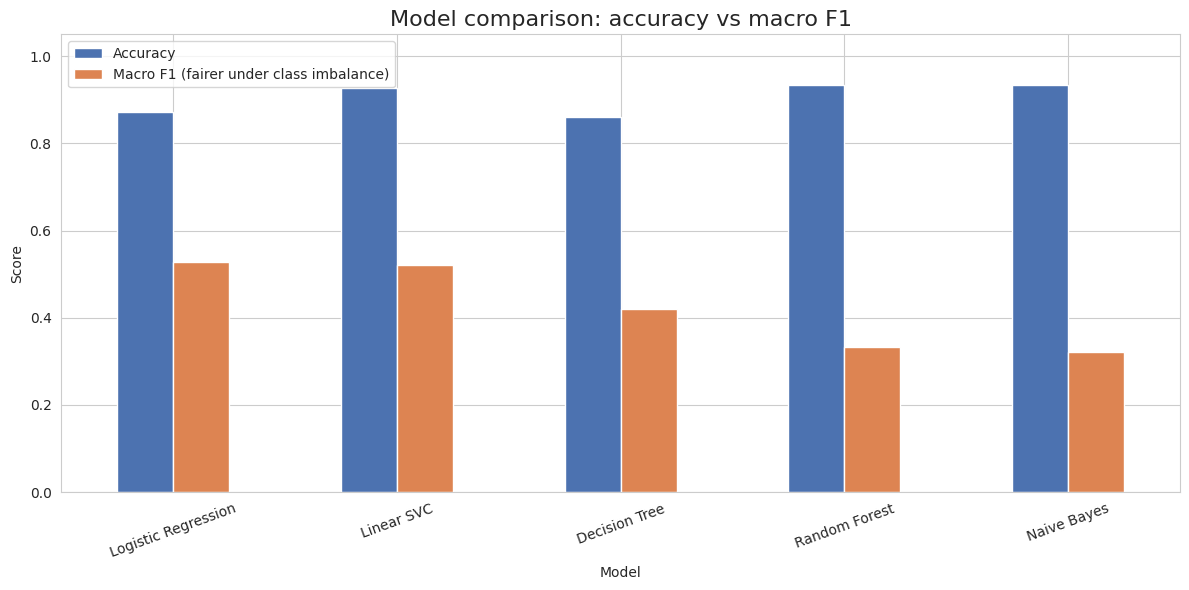

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
results_df[['accuracy', 'f1_macro']].plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_title('Model comparison: accuracy vs macro F1', fontsize=16)
ax.set_ylabel('Score')
ax.set_xlabel('Model')
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(['Accuracy', 'Macro F1 (fairer under class imbalance)'])
plt.tight_layout()
plt.show()

## 8. Closer look at the best model

Accuracy can look great while the model is quietly ignoring the minority classes (Neutral/Negative). The confusion matrix shows exactly where it's making mistakes.

Best model by macro F1: Logistic Regression


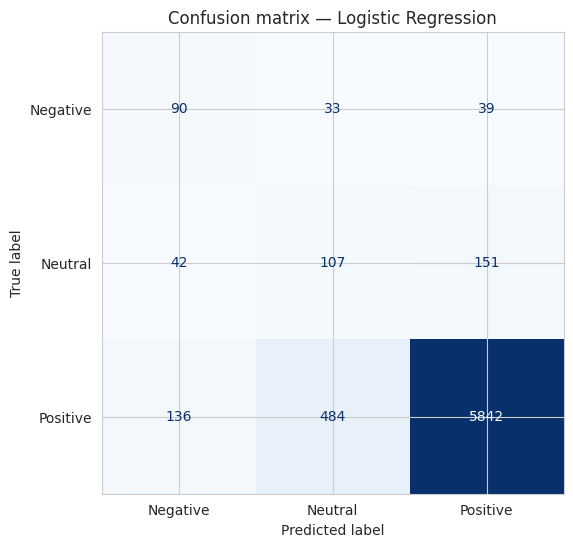

In [17]:
best_model_name = results_df.index[0]
best_pipeline = fitted_pipelines[best_model_name]
print("Best model by macro F1:", best_model_name)

preds = best_pipeline.predict(X_test)
labels_order = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(y_test, preds, labels=labels_order)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Confusion matrix — {best_model_name}')
plt.show()

## 9. Save the best model

Saves the whole pipeline (vectorizer + classifier together), so you can load it later and call `.predict()` directly on raw-ish text (just run it through `clean_text` first).

In [18]:
joblib.dump(best_pipeline, 'best_sentiment_model.joblib')
print(f"Saved {best_model_name} pipeline to best_sentiment_model.joblib")

# Example of reusing it later:
# loaded = joblib.load('best_sentiment_model.joblib')
# loaded.predict([clean_text("This tablet is amazing, my kids love it!")])

Saved Logistic Regression pipeline to best_sentiment_model.joblib


## Where to go from here

- **More data per class**: Neutral/Negative reviews are naturally rare here. If you want a model that's genuinely good at catching negative sentiment (often the more business-critical class), consider oversampling the minority classes (e.g. `imblearn.over_sampling.SMOTE` on the TF-IDF features) or collecting more negative examples.
- **Cross-validation**: this notebook uses a single train/test split for clarity. For a more robust estimate, wrap the pipelines in `cross_val_score` or `StratifiedKFold`.
- **Hyperparameter tuning**: `GridSearchCV`/`RandomizedSearchCV` over `TfidfVectorizer(ngram_range, max_features)` and each classifier's regularization strength would likely move the needle more than trying additional model types.
- **Try combining `reviews.title` + `reviews.text`**: titles are short but often carry strong sentiment signal ("Terrible!", "Love it!") and could help the minority classes.


In [19]:
senti_data['combined_text'] = (
    senti_data['reviews.title'].fillna('') + ' ' + senti_data['reviews.text'].fillna('')
)
senti_data['clean_text'] = senti_data['combined_text'].apply(clean_text)
senti_data = senti_data[senti_data['clean_text'].str.len() > 0].reset_index(drop=True)

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)),
        ("clf", clf),
    ])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_results[name] = {"f1_macro_mean": scores.mean(), "f1_macro_std": scores.std()}
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(cv_results).T.sort_values("f1_macro_mean", ascending=False)

Naive Bayes: 0.322 ± 0.000
Logistic Regression: 0.530 ± 0.011
Linear SVC: 0.509 ± 0.016
Decision Tree: 0.415 ± 0.009


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest: 0.329 ± 0.003


,f1_macro_mean,f1_macro_std
Logistic Regression,0.529720,0.011295
Linear SVC,0.508956,0.015655
Decision Tree,0.415305,0.009204
Random Forest,0.329380,0.003157
Naive Bayes,0.321834,0.000010


In [21]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [5000, 10000, None],
    "clf__C": [0.1, 1, 10],
}

grid = GridSearchCV(pipe, param_grid, scoring="f1_macro", cv=5, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV macro F1:", grid.best_score_)

best_tuned_pipeline = grid.best_estimator_
preds = best_tuned_pipeline.predict(X_test)
print(classification_report(y_test, preds, zero_division=0))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best params: {'clf__C': 1, 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 2)}
Best CV macro F1: 0.5391903205436324
              precision    recall  f1-score   support

    Negative       0.36      0.54      0.43       162
     Neutral       0.19      0.34      0.24       300
    Positive       0.97      0.92      0.94      6462

    accuracy                           0.88      6924
   macro avg       0.50      0.60      0.54      6924
weighted avg       0.92      0.88      0.90      6924



In [22]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

smote_pipe.fit(X_train, y_train)
preds = smote_pipe.predict(X_test)
print(classification_report(y_test, preds, zero_division=0))
print("Macro F1:", f1_score(y_test, preds, average="macro"))

              precision    recall  f1-score   support

    Negative       0.37      0.52      0.43       162
     Neutral       0.19      0.29      0.23       300
    Positive       0.96      0.93      0.95      6462

    accuracy                           0.89      6924
   macro avg       0.51      0.58      0.54      6924
weighted avg       0.92      0.89      0.90      6924

Macro F1: 0.5361888900213939


In [23]:
# Collect everything you've tried into one comparison
final_results = {
    "Baseline best (from earlier)": results[best_model_name],
    "With title+text combined": {"accuracy": accuracy_score(y_test, preds), "f1_macro": f1_score(y_test, preds, average="macro")},
    "Tuned (GridSearchCV)": {"accuracy": accuracy_score(y_test, grid.best_estimator_.predict(X_test)), "f1_macro": grid.best_score_},
    "SMOTE": {"accuracy": accuracy_score(y_test, smote_pipe.predict(X_test)), "f1_macro": f1_score(y_test, smote_pipe.predict(X_test), average="macro")},
}
pd.DataFrame(final_results).T.sort_values("f1_macro", ascending=False)

,accuracy,f1_macro
Tuned (GridSearchCV),0.884027,0.539190
With title+text combined,0.892692,0.536189
SMOTE,0.892692,0.536189
Baseline best (from earlier),0.872184,0.528458
